<a href="https://colab.research.google.com/github/n-schiozer/met_comp_economistas_unesp/blob/main/Aula_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 9 — Pandas: filtragem, operações condicionais e gráficos


Esta aula **continua a Aula 8**, a partir da seção de filtragem. Usaremos a mesma base do **Banco Mundial — World Development Indicators (WDI)**, entre **2020 e 2024**.

**Objetivos:** selecionar observações; combinar critérios lógicos; criar faixas de inflação; agregar estatísticas por categoria; construir e interpretar gráficos de barras, linhas e dispersão.


**Fontes:** [World Bank — DataBank](https://databank.worldbank.org/source/world-development-indicators) · [McKinney, *Python for Data Analysis*, caps. 5 e 9](https://wesmckinney.com/book/) · [Pandas — visualização](https://pandas.pydata.org/docs/user_guide/visualization.html) · [Matplotlib](https://matplotlib.org/stable/).

## Preparação — mesma base da aula anterior

Execute as próximas células para construir o DataFrame `dados`. Se você já está no notebook da Aula 8 com `dados` carregado, pode começar diretamente pela **Seção 1**.

Cada linha corresponde a um país e um ano. As colunas são `ano`, `pais`, `regiao`, `pib_usd`, `populacao_total`, `inflacao_anual_pct` e `desemprego_pct`.

*A coleta de dados já foi apresentada na Aula 8. Hoje nosso foco começa após a montagem da base.*

In [ ]:
import requests                # Biblioteca para consultar APIs e páginas na internet.
import pandas as pd            # Biblioteca para manipular dados em DataFrames.

# ============================================================
# 1. DEFINIR PERÍODO E INDICADORES
# ============================================================

ano_inicial = 2020
ano_final = 2024

# Chave: nome que desejamos no DataFrame. Valor: código da API.
# Fonte: https://databank.worldbank.org/source/world-development-indicators
indicadores = {
    "pib_usd": "NY.GDP.MKTP.CD",            # PIB nominal em dólares.
    "populacao_total": "SP.POP.TOTL",       # População total.
    "inflacao_anual_pct": "FP.CPI.TOTL.ZG", # Inflação anual (%).
    "desemprego_pct": "SL.UEM.TOTL.ZS",     # Desemprego (% da força de trabalho).
}

In [ ]:
# ============================================================
# 2. OBTER INFORMAÇÕES SOBRE OS PAÍSES
# ============================================================

url_paises = "https://api.worldbank.org/v2/country"

# Solicitar dados no formato JSON e até 400 países/economias na página.
resposta = requests.get(
    url_paises,
    params={"format": "json", "per_page": 400},
    timeout=45
)
resposta.raise_for_status()  # Interrompe a execução se houver erro HTTP.
conteudo = resposta.json()   # Transforma o JSON em estruturas do Python.

# Construir uma lista de dicionários: um registro por país/economia.
# A expressão for ... if ... seleciona apenas países, excluindo agregados.
metadados = pd.DataFrame([
    {
        "codigo_pais": pais["id"],
        "pais": pais["name"],
        "regiao": pais["region"]["value"]
    }
    for pais in conteudo[1]
    if pais["region"]["value"] != "Aggregates"
])

# set() cria um conjunto de códigos únicos para verificar quais são válidos.
codigos_validos = set(metadados["codigo_pais"])

In [ ]:
# ============================================================
# 3. BAIXAR OS INDICADORES ECONÔMICOS
# ============================================================

registros = []  # Lista vazia para guardar todas as observações.

# .items() percorre cada par nome-do-indicador/código-da-API.
for coluna, codigo in indicadores.items():

    # f-string: substitui {codigo} pelo código atual do indicador.
    url = f"https://api.worldbank.org/v2/country/all/indicator/{codigo}"

    resposta = requests.get(
        url,
        params={
            "format": "json",                    # Resposta JSON.
            "source": 2,                         # World Development Indicators.
            "date": f"{ano_inicial}:{ano_final}", # Intervalo de anos.
            "per_page": 20000                    # Limite de registros por página.
        },
        timeout=45
    )
    resposta.raise_for_status()  # Verificar se o pedido foi bem-sucedido.
    conteudo = resposta.json()

    # Cada item representa um país, um ano e um indicador.
    for item in conteudo[1]:
        if item["countryiso3code"] in codigos_validos:
            registros.append({
                "codigo_pais": item["countryiso3code"],
                "ano": int(item["date"]),        # Ano convertido para inteiro.
                "indicador": coluna,              # Nome da variável.
                "valor": item["value"]           # Valor ou None (ausente).
            })

In [ ]:
# ============================================================
# 4. ORGANIZAR OS DADOS EM TABELA
# ============================================================

dados_longos = pd.DataFrame(registros)

# No formato longo, cada linha identifica país, ano, indicador e valor.
# pivot() coloca cada indicador em uma coluna; não agrega estatísticas.
dados_largos = (
    dados_longos
    .pivot(index=["codigo_pais", "ano"],
           columns="indicador", values="valor")
    .reset_index()  # Traz código e ano do índice de volta às colunas.
)

# Elimina somente o nome do eixo das colunas, sem apagar as colunas.
dados_largos.columns.name = None

In [ ]:
# ============================================================
# 5. JUNTAR METADADOS E ORGANIZAR O DATAFRAME FINAL
# ============================================================

dados = (
    dados_largos
    # merge(): juntar indicadores e metadados usando o código do país.
    .merge(metadados, on="codigo_pais", how="inner",
           validate="many_to_one")
    # Manter e ordenar as sete colunas de interesse.
    [["ano", "pais", "regiao", "pib_usd", "populacao_total",
      "inflacao_anual_pct", "desemprego_pct"]]
    .sort_values(["ano", "pais"])  # Ordenar por ano e país.
    .reset_index(drop=True)        # Reiniciar o índice sem preservar o antigo.
)

print("Dimensões:", dados.shape)
print("Países:", dados["pais"].nunique())
print("Valores ausentes por coluna:")
print(dados.isna().sum())

dados.head(10)

Dimensões: (1085, 7)
Países: 217
Valores ausentes por coluna:
ano                     0
pais                    0
regiao                  0
pib_usd                52
populacao_total         0
inflacao_anual_pct    195
desemprego_pct        159
dtype: int64


,ano,pais,regiao,pib_usd,populacao_total,inflacao_anual_pct,desemprego_pct
0,2020,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",1.995593e+10,39068979.0,5.601888,11.710
1,2020,Albania,Europe & Central Asia,1.524146e+10,2528480.0,1.620887,11.639
2,2020,Algeria,"Middle East, North Africa, Afghanistan & Pakistan",1.648734e+11,44042091.0,2.415131,14.080
3,2020,American Samoa,East Asia & Pacific,7.210000e+08,49761.0,NaN,NaN
4,2020,Andorra,Europe & Central Asia,2.891001e+09,77380.0,NaN,NaN
5,2020,Angola,Sub-Saharan Africa,5.851203e+10,33451132.0,22.271539,16.696
6,2020,Antigua and Barbuda,Latin America & Caribbean,1.411637e+09,91846.0,0.625990,NaN
7,2020,Argentina,Latin America & Caribbean,3.857405e+11,45191965.0,42.015095,11.461
8,2020,Armenia,Europe & Central Asia,1.264170e+10,2961500.0,1.211436,18.175
9,2020,Aruba,Latin America & Caribbean,2.461056e+09,108587.0,NaN,NaN


---
## 1. Retomada: transformação e agrupamento

Na aula anterior calculamos indicadores novos e resumimos dados por região com `groupby()` e `agg()`. Vamos relembrar com o PIB per capita, sem reexplicar toda a API.

In [ ]:
# Selecionar apenas as observações de 2024
dados_2024 = dados.loc[dados["ano"] == 2024].copy()

# Calcular o PIB per capita
dados_2024["pib_per_capita_usd"] = (
    dados_2024["pib_usd"] / dados_2024["populacao_total"]
)

In [ ]:
agrupamento_2024_região = dados_2024.groupby("regiao", as_index=False)

# Média simples entre países, não PIB regional dividido pela população regional
resumo_regiao = (
    agrupamento_2024_região
    .agg(
        pib_per_capita_medio=("pib_per_capita_usd", "mean"),
        inflacao_media=("inflacao_anual_pct", "mean")
    )
    .round(2)
)

display(resumo_regiao)

,regiao,pib_per_capita_medio,inflacao_media
0,East Asia & Pacific,19083.92,3.05
1,Europe & Central Asia,43355.75,4.32
2,Latin America & Caribbean,18491.76,11.46
3,"Middle East, North Africa, Afghanistan & Pakistan",18854.23,9.52
4,North America,94478.60,2.67
5,South Asia,4799.74,3.97
6,Sub-Saharan Africa,2681.58,10.48


---
## 2. Filtragem: selecionar observações

Filtrar significa **escolher linhas** segundo uma condição lógica. A sintaxe `dados.loc[condicao, colunas]` seleciona linhas e, opcionalmente, as colunas que queremos exibir.

**Operadores:** `&` significa **E**; `|` significa **OU**; `~` significa **NÃO**. Use parênteses em cada comparação.

### 2.1 Uma condição: um ano ou um país

In [ ]:
# Selecionar o ano de 2024
dados_2024 = dados.loc[dados["ano"] == 2024].copy()

# Mostrar apenas algumas colunas
display(dados_2024[["ano", "pais", "inflacao_anual_pct"]].head(10))

# Selecionar todas as observações de um país (nome conforme o WDI)
dados_brasil = dados.loc[dados["pais"] == "Brazil"]

display(dados_brasil[["ano", "pais", "inflacao_anual_pct", "desemprego_pct"]])

,ano,pais,inflacao_anual_pct
868,2024,Afghanistan,-6.601186
869,2024,Albania,2.215874
870,2024,Algeria,4.046115
871,2024,American Samoa,NaN
872,2024,Andorra,NaN
873,2024,Angola,28.240495
874,2024,Antigua and Barbuda,6.198867
875,2024,Argentina,219.883929
876,2024,Armenia,0.269512
877,2024,Aruba,NaN


,ano,pais,inflacao_anual_pct,desemprego_pct
26,2020,Brazil,3.211768,13.697
243,2021,Brazil,8.301660,13.158
460,2022,Brazil,9.280106,9.231
677,2023,Brazil,4.593563,7.947
894,2024,Brazil,4.367464,6.801


### 2.2 Duas condições: ano **E** inflação elevada

In [ ]:
display(dados.head())

# Selecionando colunas de forma correta (especificando todas as linhas com ":")
inflacao_2024 = dados.loc[:, ["ano", "pais", "inflacao_anual_pct"]]

# Por que quando uso .loc preciso [:,["ano", "pais", "inflacao_anual_pct"]] e

# não preciso quando: dados_2024[["ano", "pais", "inflacao_anual_pct"]] ?

display(inflacao_2024)

,ano,pais,regiao,pib_usd,populacao_total,inflacao_anual_pct,desemprego_pct
0,2020,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",1.995593e+10,39068979.0,5.601888,11.710
1,2020,Albania,Europe & Central Asia,1.524146e+10,2528480.0,1.620887,11.639
2,2020,Algeria,"Middle East, North Africa, Afghanistan & Pakistan",1.648734e+11,44042091.0,2.415131,14.080
3,2020,American Samoa,East Asia & Pacific,7.210000e+08,49761.0,NaN,NaN
4,2020,Andorra,Europe & Central Asia,2.891001e+09,77380.0,NaN,NaN


,ano,pais,inflacao_anual_pct
0,2020,Afghanistan,5.601888
1,2020,Albania,1.620887
2,2020,Algeria,2.415131
3,2020,American Samoa,NaN
4,2020,Andorra,NaN
...,...,...,...
1080,2024,Virgin Islands (U.S.),NaN
1081,2024,West Bank and Gaza,53.669146
1082,2024,"Yemen, Rep.",NaN
1083,2024,Zambia,14.985626


In [ ]:
# Países com inflação de pelo menos 10% em 2024
inflacao_alta_2024 = dados.loc[
    (dados["ano"] == 2024) & (dados["inflacao_anual_pct"] >= 10), # A vírgula separa os critérios para linhas e os critérios para colunas
    ["pais","ano", "regiao", "inflacao_anual_pct"]
]

inflacao_alta_2024 = (
    inflacao_alta_2024
    .sort_values("inflacao_anual_pct", ascending=False) # Critérios de ordenação
    .reset_index(drop=True) # Cria novo index
)

display(inflacao_alta_2024)
print("Número de países:", inflacao_alta_2024.shape[0])

,pais,ano,regiao,inflacao_anual_pct
0,Argentina,2024,Latin America & Caribbean,219.883929
1,South Sudan,2024,Sub-Saharan Africa,91.440822
2,Turkiye,2024,Europe & Central Asia,58.506449
3,West Bank and Gaza,2024,"Middle East, North Africa, Afghanistan & Pakistan",53.669146
4,Lebanon,2024,"Middle East, North Africa, Afghanistan & Pakistan",45.243042
5,Nigeria,2024,Sub-Saharan Africa,33.241659
6,"Iran, Islamic Rep.",2024,"Middle East, North Africa, Afghanistan & Pakistan",32.455871
7,Malawi,2024,Sub-Saharan Africa,32.179650
8,Sierra Leone,2024,Sub-Saharan Africa,28.633750
9,"Egypt, Arab Rep.",2024,"Middle East, North Africa, Afghanistan & Pakistan",28.270590


Número de países: 22


### 2.3 Condições alternativas (`|`), listas (`isin`) e dados ausentes

In [ ]:
# Inflação > 8% OU desemprego > 12% em 2024
selecionados_2024 = dados.loc[
    (dados["ano"] == 2024) & # Condicional E para as linhas que são selecionadas
    ((dados["inflacao_anual_pct"] > 8) | (dados["desemprego_pct"] > 12)), # Separação do que é linha e o que é coluna
    ["pais", "regiao", "inflacao_anual_pct", "desemprego_pct"]
]
display(selecionados_2024.head(15))



,pais,regiao,inflacao_anual_pct,desemprego_pct
868,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",-6.601186,13.687
873,Angola,Sub-Saharan Africa,28.240495,14.020
875,Argentina,Latin America & Caribbean,219.883929,7.150
876,Armenia,Europe & Central Asia,0.269512,12.405
883,Bangladesh,South Asia,10.465748,3.635
893,Botswana,Sub-Saharan Africa,2.818351,23.810
899,Burundi,Sub-Saharan Africa,20.212493,0.915
906,Chad,Sub-Saharan Africa,8.899507,1.053
913,"Congo, Rep.",Sub-Saharan Africa,3.091436,19.895
922,Djibouti,"Middle East, North Africa, Afghanistan & Pakistan",2.112012,26.007


In [ ]:
# Brasil, Argentina e México, em 2023 ou 2024

# No Pandas, o método .isin() serve para verificar se os valores de uma coluna pertencem a uma lista de valores.

# .isin() verifica, para cada linha, se o país está na lista.

display(dados["pais"].isin(["Brazil", "Argentina", "Mexico"]))

,pais
0,False
1,False
2,False
3,False
4,False
...,...
1080,False
1081,False
1082,False
1083,False


In [ ]:
# Seleção apenas de dados de países escolhidos

paises_escolhidos = dados.loc[
    dados["pais"].isin(["Brazil", "Argentina", "Mexico"]) &
    dados["ano"].isin([2023, 2024]),
    ["ano", "pais", "inflacao_anual_pct"]
].reset_index(drop=True)

display(paises_escolhidos)

In [ ]:
# is.na() é a mesma lógica do is.in(), mas, verifica se valores estão ausentes (NaN)


# Países sem informação de inflação em 2024
sem_inflacao = dados.loc[
    (dados["ano"] == 2024) & dados["inflacao_anual_pct"].isna(),
    ["pais", "regiao", "inflacao_anual_pct"]
]

print("Observações sem inflação:", sem_inflacao.shape[0])
display(sem_inflacao.head(10))

# Condição nomeada e sua negação (~)
condicao = (dados_2024["inflacao_anual_pct"] >= 10)
print("Países com inflação >= 10%:", condicao.sum())

# Observação: o oposto inclui valores ausentes; não é sinônimo de inflação < 10%.
display(dados_2024.loc[~condicao, ["pais", "inflacao_anual_pct"]].head(10))

Observações sem inflação: 41


,pais,regiao,inflacao_anual_pct
871,American Samoa,East Asia & Pacific,NaN
872,Andorra,Europe & Central Asia,NaN
877,Aruba,Latin America & Caribbean,NaN
889,Bermuda,North America,NaN
895,British Virgin Islands,Latin America & Caribbean,NaN
904,Cayman Islands,Latin America & Caribbean,NaN
907,Channel Islands,Europe & Central Asia,NaN
912,"Congo, Dem. Rep.",Sub-Saharan Africa,NaN
917,Cuba,Latin America & Caribbean,NaN
918,Curacao,Latin America & Caribbean,NaN


Países com inflação >= 10%: 22


,pais,inflacao_anual_pct
868,Afghanistan,-6.601186
869,Albania,2.215874
870,Algeria,4.046115
871,American Samoa,NaN
872,Andorra,NaN
874,Antigua and Barbuda,6.198867
876,Armenia,0.269512
877,Aruba,NaN
878,Australia,3.166567
879,Austria,2.937916


### Exercício 1 — filtros

1. Filtre os países da **América Latina e Caribe** ("Latin America & Caribbean	") em **2024** com inflação informada. Cuidado com o espaço no final do filtro!
2. Ordene os países selecionados pela **maior inflação**.
3. Selecione países de **2024** com **inflação maior que 8% OU desemprego maior que 12%**. Conte quantas observações foram selecionadas.

Utilize `.loc[]`, `&`, `|`, `.notna()`, `.sort_values()` e `.shape[0]`.

In [ ]:
# EXERCÍCIO 1 — complete aqui.



,pais,regiao,inflacao_anual_pct
1050,St. Lucia,Latin America & Caribbean,-0.674241
914,Costa Rica,Latin America & Caribbean,-0.412853
881,"Bahamas, The",Latin America & Caribbean,0.409162
1064,Trinidad and Tobago,Latin America & Caribbean,0.526885
1019,Panama,Latin America & Caribbean,0.692107
927,El Salvador,Latin America & Caribbean,0.853782
946,Grenada,Latin America & Caribbean,1.086154
884,Barbados,Latin America & Caribbean,1.446437
925,Ecuador,Latin America & Caribbean,1.547325
1022,Peru,Latin America & Caribbean,2.007707


Observações selecionadas: 49


,pais,inflacao_anual_pct,desemprego_pct
868,Afghanistan,-6.601186,13.687
873,Angola,28.240495,14.020
875,Argentina,219.883929,7.150
876,Armenia,0.269512,12.405
883,Bangladesh,10.465748,3.635
893,Botswana,2.818351,23.810
899,Burundi,20.212493,0.915
906,Chad,8.899507,1.053
913,"Congo, Rep.",3.091436,19.895
922,Djibouti,2.112012,26.007


---
## 3. Operações condicionais: criar faixas de inflação

Uma operação condicional não precisa retirar linhas: podemos **manter os países e atribuir uma categoria** a cada observação conforme seu valor de inflação.

Para 2024, classificaremos os países nas seguintes faixas:

| Faixa | Critério |
|---|---|
| 1 | Inflação menor que 2% |
| 2 | Inflação de 2% até menos de 5% |
| 3 | Inflação de 5% até 10% (inclusive) |
| 4 | Inflação maior que 10% |

**Importante:** não devemos classificar automaticamente países sem informação como países de inflação baixa.

In [ ]:
# Considerar 2024 e excluir ausências apenas das variáveis necessárias
dados_2024_validos = dados.loc[
    (dados["ano"] == 2024) &
    dados["inflacao_anual_pct"].notna() &
    dados["desemprego_pct"].notna()
].copy()

# Iniciar coluna de classificação
# Todas as observações dessa tabela têm inflação informada
dados_2024_validos["faixa_inflacao"] = ""

display(dados_2024_validos)

,ano,pais,regiao,pib_usd,populacao_total,inflacao_anual_pct,desemprego_pct,faixa_inflacao
868,2024,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",1.777851e+10,42647492.0,-6.601186,13.687,
869,2024,Albania,Europe & Central Asia,2.703747e+10,2377128.0,2.215874,10.689,
870,2024,Algeria,"Middle East, North Africa, Afghanistan & Pakistan",2.693223e+11,46814308.0,4.046115,11.655,
873,2024,Angola,Sub-Saharan Africa,1.030805e+11,37885849.0,28.240495,14.020,
875,2024,Argentina,Latin America & Caribbean,6.383655e+11,45696159.0,219.883929,7.150,
...,...,...,...,...,...,...,...,...
1075,2024,Uruguay,Latin America & Caribbean,8.232286e+10,3386588.0,4.849144,8.209,
1076,2024,Uzbekistan,Europe & Central Asia,1.213561e+11,36361859.0,9.628255,4.439,
1077,2024,Vanuatu,East Asia & Pacific,1.297957e+09,327777.0,1.143489,4.988,
1079,2024,Viet Nam,East Asia & Pacific,4.763246e+11,100987686.0,3.621093,1.602,


In [ ]:
# Faixa 1 — inflação menor que 2%
dados_2024_validos.loc[
    dados_2024_validos["inflacao_anual_pct"] < 2,
    "faixa_inflacao"
] = "1. Menor que 2%"

# Faixa 2 — de 2% a menos de 5%
dados_2024_validos.loc[
    (dados_2024_validos["inflacao_anual_pct"] >= 2) &
    (dados_2024_validos["inflacao_anual_pct"] < 5),
    "faixa_inflacao"
] = "2. De 2% a menos de 5%"

# Faixa 3 — de 5% até 10% (inclusive)
dados_2024_validos.loc[
    (dados_2024_validos["inflacao_anual_pct"] >= 5) &
    (dados_2024_validos["inflacao_anual_pct"] <= 10),
    "faixa_inflacao"
] = "3. De 5% até 10%"

# Faixa 4 — superior a 10%
dados_2024_validos.loc[
    dados_2024_validos["inflacao_anual_pct"] > 10,
    "faixa_inflacao"
] = "4. Maior que 10%"

display(dados_2024_validos[[
    "pais", "inflacao_anual_pct", "desemprego_pct", "faixa_inflacao"
]].head(15))

,pais,inflacao_anual_pct,desemprego_pct,faixa_inflacao
868,Afghanistan,-6.601186,13.687,1. Menor que 2%
869,Albania,2.215874,10.689,2. De 2% a menos de 5%
870,Algeria,4.046115,11.655,2. De 2% a menos de 5%
873,Angola,28.240495,14.020,4. Maior que 10%
875,Argentina,219.883929,7.150,4. Maior que 10%
876,Armenia,0.269512,12.405,1. Menor que 2%
878,Australia,3.166567,3.942,2. De 2% a menos de 5%
879,Austria,2.937916,5.200,2. De 2% a menos de 5%
880,Azerbaijan,2.212172,5.648,2. De 2% a menos de 5%
881,"Bahamas, The",0.409162,9.049,1. Menor que 2%


### 3.1 Agregar por faixa: o desemprego médio varia com a inflação?

In [ ]:
resumo_inflacao = (
    dados_2024_validos.groupby("faixa_inflacao", as_index=False)
    .agg(
        desemprego_medio_pct=("desemprego_pct", "mean"),
        numero_paises=("pais", "count")
    )
    .sort_values("faixa_inflacao")
    .round(2)
    .reset_index(drop=True)
)

display(resumo_inflacao)

,faixa_inflacao,desemprego_medio_pct,numero_paises
0,1. Menor que 2%,6.15,46
1,2. De 2% a menos de 5%,6.89,81
2,3. De 5% até 10%,5.19,18
3,4. Maior que 10%,6.17,19


In [ ]:
resumo_inflacao["proporção"] = (
    resumo_inflacao["numero_paises"]
    / resumo_inflacao["numero_paises"].sum()
    * 100
)

display(resumo_inflacao)


,faixa_inflacao,desemprego_medio_pct,numero_paises,proporção
0,1. Menor que 2%,6.15,46,28.048780
1,2. De 2% a menos de 5%,6.89,81,49.390244
2,3. De 5% até 10%,5.19,18,10.975610
3,4. Maior que 10%,6.17,19,11.585366


### 3.2 Comparar faixas **dentro de cada região**

In [ ]:
resumo_por_regiao = (
    dados_2024_validos.groupby(["regiao", "faixa_inflacao"], as_index=False)
    .agg(
        desemprego_medio_pct=("desemprego_pct", "mean"),
        numero_paises=("pais", "count")
    )
    .sort_values(["regiao", "faixa_inflacao"])
    .round(2)
)

display(resumo_por_regiao)

,regiao,faixa_inflacao,desemprego_medio_pct,numero_paises
0,East Asia & Pacific,1. Menor que 2%,3.06,9
1,East Asia & Pacific,2. De 2% a menos de 5%,3.00,13
2,East Asia & Pacific,3. De 5% até 10%,5.16,1
3,East Asia & Pacific,4. Maior que 10%,1.17,1
4,Europe & Central Asia,1. Menor que 2%,7.42,12
5,Europe & Central Asia,2. De 2% a menos de 5%,6.16,27
6,Europe & Central Asia,3. De 5% até 10%,4.03,6
7,Europe & Central Asia,4. Maior que 10%,8.80,1
8,Latin America & Caribbean,1. Menor que 2%,6.39,8
9,Latin America & Caribbean,2. De 2% a menos de 5%,7.21,13


### Exercício 2 — classificação condicional

1. Crie `faixa_desemprego` em 2024 com as categorias **"Até 8%"** e **"Acima de 8%"**; exclua as observações com desemprego ausente antes de classificar.
2. Calcule a **inflação média** e o **número de países com inflação informada** em cada categoria.
3. Repita a agregação separando também por `regiao`.

In [ ]:
# EXERCÍCIO 2 — complete aqui.

---
## 4. Visualização com Pandas e Matplotlib

**Pergunta:** qual formato é mais adequado à informação que queremos apresentar?

- **Barras:** comparação de países ou categorias.
- **Linhas:** evolução de uma variável ao longo do tempo.
- **Dispersão:** relação visual entre duas variáveis quantitativas.

Usaremos `.plot()` do Pandas para criar gráficos e `matplotlib.pyplot` para adicionar títulos, eixos e ajustes simples.

In [ ]:
# Importar o módulo pyplot da biblioteca Matplotlib
# Por convenção, utilizamos o apelido "plt"

import matplotlib.pyplot as plt

### 4.1 Barras horizontais — os dez países com maior inflação em 2024

Primeiro construímos o ranking, depois o gráfico. O objetivo é aprender a representar visualmente uma tabela ordenada.

,pais,inflacao_anual_pct
875,Argentina,219.883929
1046,South Sudan,91.440822
1066,Turkiye,58.506449
1081,West Bank and Gaza,53.669146
978,Lebanon,45.243042
1012,Nigeria,33.241659
959,"Iran, Islamic Rep.",32.455871
987,Malawi,32.179650
1038,Sierra Leone,28.633750
926,"Egypt, Arab Rep.",28.270590


NameError: name 'plt' is not defined

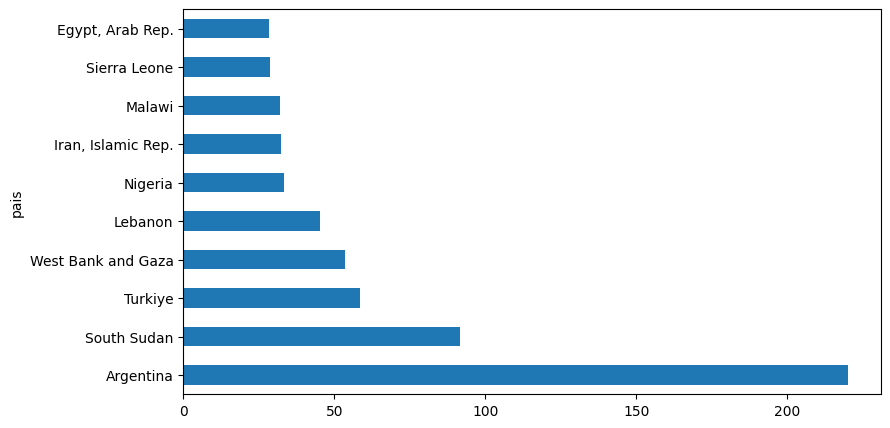

In [ ]:
# Remover observações sem inflação e selecionar os 10 países
# com maior inflação anual em 2024
top10_inflacao = (
    dados_2024[["pais", "inflacao_anual_pct"]]
    .dropna(subset=["inflacao_anual_pct"])
    .sort_values("inflacao_anual_pct", ascending=False)
    .head(10)
)

display(top10_inflacao)

# -------------------------------------------------------
# CRIAÇÃO DO GRÁFICO COM PANDAS
# -------------------------------------------------------

top10_inflacao.plot( # .plot : Cria um gráfico a partir do DataFrame.
    x="pais",                   # Variável que identifica os países
    y="inflacao_anual_pct",     # Variável numérica representada pelas barras
    kind="barh",                # Tipo de gráfico: barras horizontais
    figsize=(9, 5),             # Tamanho da figura: 9 polegadas de largura e 5 de altura
    legend=False                # Não exibir a legenda
)

# -------------------------------------------------------
# PERSONALIZAÇÃO DO GRÁFICO COM MATPLOTLIB (plt)
# -------------------------------------------------------

# plt.title(): define o título principal do gráfico.
# O texto informado entre parênteses será exibido acima da figura.
plt.title("Dez países com maior inflação — 2024")

# plt.xlabel(): define o nome do eixo horizontal (eixo X).
# Neste gráfico, o eixo horizontal apresenta os valores da inflação.
plt.xlabel("Inflação anual (%)")

# plt.ylabel(): define o nome do eixo vertical (eixo Y).
# Como utilizamos barras horizontais, o eixo vertical identifica os países.
plt.ylabel("País")

# plt.tight_layout(): ajusta automaticamente os espaçamentos da figura.
# Evita que títulos, nomes dos eixos e rótulos dos países
# fiquem cortados ou sobrepostos às margens do gráfico.
plt.tight_layout()

# plt.show(): exibe o gráfico na saída do Python.
# Em ambientes como Jupyter Notebook e Google Colab,
# frequentemente o gráfico aparece mesmo sem este comando.
# Entretanto, utilizá-lo deixa explícito o momento de exibição.
plt.show()

### 4.2 Barras por categoria — desemprego médio por faixa de inflação

Vamos transformar a tabela de `groupby()` em um gráfico. **Atenção:** as médias são simples entre países, não ponderadas pela população ou pela força de trabalho.

,faixa_inflacao,desemprego_medio_pct,numero_paises,proporção
0,1. Menor que 2%,6.15,46,28.048780
1,2. De 2% a menos de 5%,6.89,81,49.390244
2,3. De 5% até 10%,5.19,18,10.975610
3,4. Maior que 10%,6.17,19,11.585366


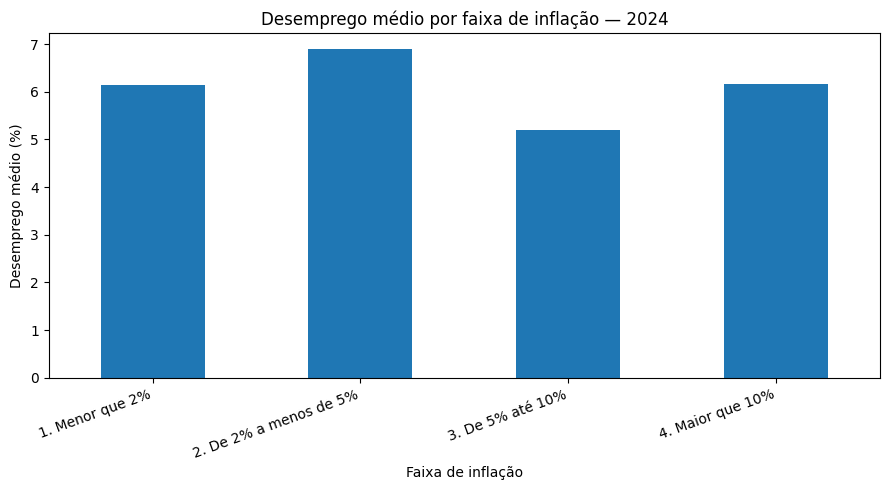

In [ ]:
display(resumo_inflacao)

resumo_inflacao.plot(
    x="faixa_inflacao",
    y="desemprego_medio_pct",
    kind="bar",
    figsize=(9, 5),
    legend=False
)

plt.title("Desemprego médio por faixa de inflação — 2024")
plt.xlabel("Faixa de inflação")
plt.ylabel("Desemprego médio (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### 4.3 Linhas — trajetória da inflação: Brasil e Argentina (2020–2024)

Os anos ficam no eixo horizontal. Como nosso painel tem múltiplos países, precisamos escolher quais séries queremos comparar.

pais,Argentina,Brazil
ano,,
2020,42.015095,3.211768
2021,48.409379,8.301660
2022,72.430758,9.280106
2023,133.488936,4.593563
2024,219.883929,4.367464


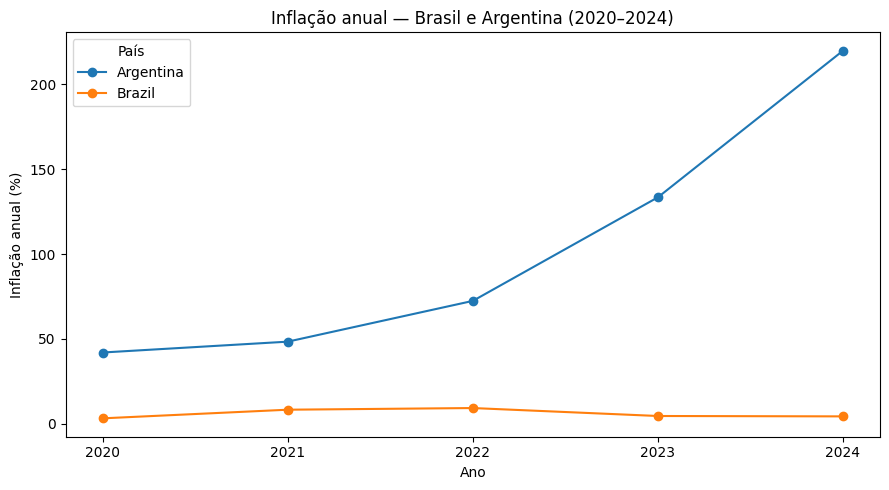

In [ ]:
# Selecionar apenas os países desejados
comparacao = dados.loc[
    dados["pais"].isin(["Brazil", "Argentina"]),
    ["ano", "pais", "inflacao_anual_pct"]
]

# Reorganizar: linhas = anos; colunas = países
serie_inflacao = comparacao.pivot(
    index="ano", columns="pais", values="inflacao_anual_pct"
).sort_index()

display(serie_inflacao)

serie_inflacao.plot(kind="line", marker="o", figsize=(9, 5))
plt.title("Inflação anual — Brasil e Argentina (2020–2024)")
plt.xlabel("Ano")
plt.ylabel("Inflação anual (%)")
plt.xticks(sorted(serie_inflacao.index))
plt.legend(title="País")
plt.tight_layout()
plt.show()

### 4.4 Dispersão — inflação e desemprego (introdução)

O gráfico de dispersão permite examinar se países com inflação maior também tendem a registrar desemprego maior ou menor.

**Hoje apenas vamos construir e ler o gráfico.** Na aula 10, usaremos correlações, distribuições e outliers para aprofundar a investigação.

Países no gráfico: 164


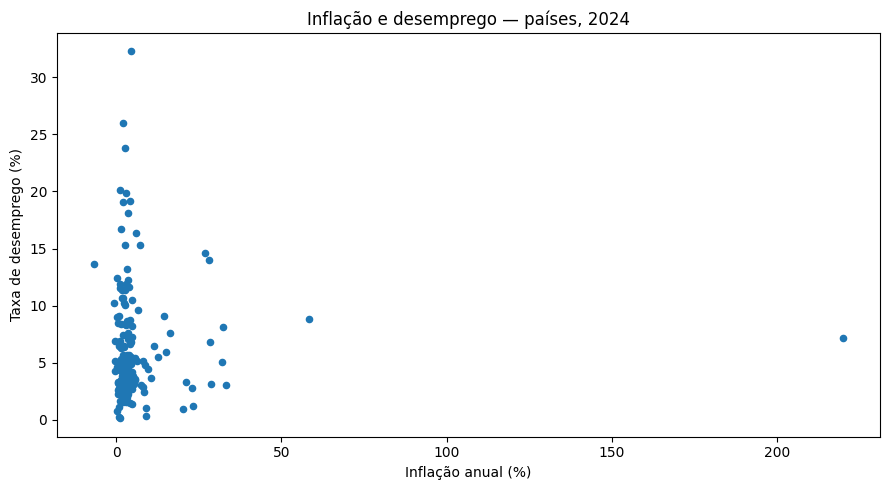

In [ ]:
# Selecionar países com as duas informações presentes
pares_validos = dados_2024[[
    "pais", "inflacao_anual_pct", "desemprego_pct"
]].dropna(subset=["inflacao_anual_pct", "desemprego_pct"])

print("Países no gráfico:", len(pares_validos))

pares_validos.plot.scatter(
    x="inflacao_anual_pct",
    y="desemprego_pct",
    figsize=(9, 5)
)

plt.title("Inflação e desemprego — países, 2024")
plt.xlabel("Inflação anual (%)")
plt.ylabel("Taxa de desemprego (%)")
plt.tight_layout()
plt.show()

Países no gráfico: 150


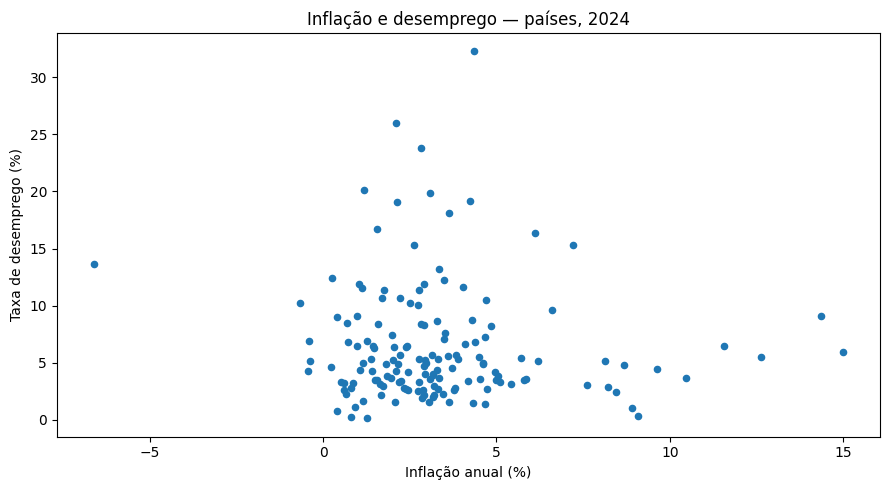

In [ ]:
# Selecionar países com as duas informações presentes
pares_validos = dados_2024.loc[dados_2024["inflacao_anual_pct"] < 15,[
    "pais", "inflacao_anual_pct", "desemprego_pct"
]].dropna(subset=["inflacao_anual_pct", "desemprego_pct"])

print("Países no gráfico:", len(pares_validos))

pares_validos.plot.scatter(
    x="inflacao_anual_pct",
    y="desemprego_pct",
    figsize=(9, 5)
)

plt.title("Inflação e desemprego — países, 2024")
plt.xlabel("Inflação anual (%)")
plt.ylabel("Taxa de desemprego (%)")
plt.tight_layout()
plt.show()

**Para discussão:** algum país com inflação muito elevada está comprimindo visualmente os demais pontos? O que acontece com a leitura quando mudamos a escala do eixo horizontal? **Não remova outliers sem justificativa econômica.**

### Exercício 3 — gráficos

1. Crie um gráfico de **barras horizontais** com as **dez maiores taxas de desemprego** de 2024.
2. Faça um gráfico de **linhas** com a inflação de **Brasil, México e Argentina** entre 2020 e 2024.
3. Inclua título e rótulos dos eixos em cada gráfico.

In [ ]:
display(dados_2024.columns)

Index(['ano', 'pais', 'regiao', 'pib_usd', 'populacao_total',
       'inflacao_anual_pct', 'desemprego_pct', 'pib_per_capita_usd'],
      dtype='object')

,pais,inflacao_anual_pct
875,Argentina,219.883929
1046,South Sudan,91.440822
1066,Turkiye,58.506449
1081,West Bank and Gaza,53.669146
978,Lebanon,45.243042
1012,Nigeria,33.241659
959,"Iran, Islamic Rep.",32.455871
987,Malawi,32.179650
1038,Sierra Leone,28.633750
926,"Egypt, Arab Rep.",28.270590


<Axes: ylabel='pais'>

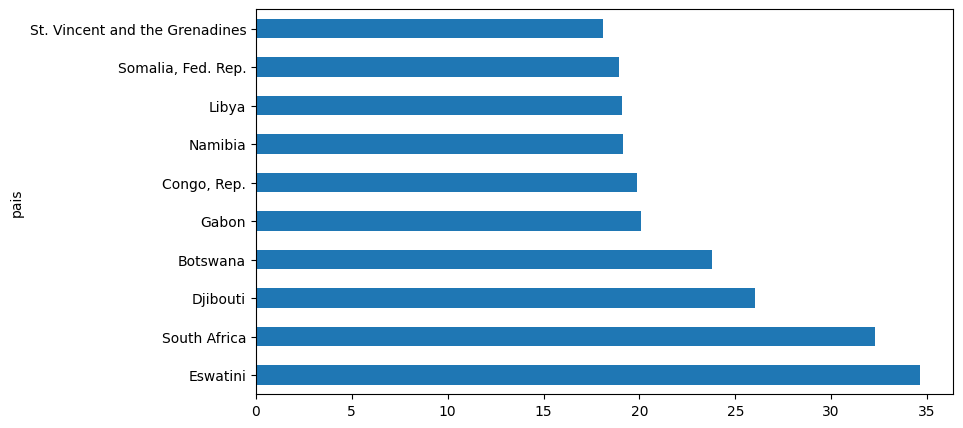

In [ ]:
# EXERCÍCIO 3 — complete aqui.



top10_desemprego = (
    dados_2024[["pais", "desemprego_pct"]]
    .dropna(subset=["desemprego_pct"])
    .sort_values("desemprego_pct", ascending=False)
    .head(10)
)

display(top10_inflacao)

top10_desemprego.plot( # .plot : Cria um gráfico a partir do DataFrame.
    x="pais",                   # Variável que identifica os países
    y="desemprego_pct",     # Variável numérica representada pelas barras
    kind="barh",                # Tipo de gráfico: barras horizontais
    figsize=(9, 5),             # Tamanho da figura: 9 polegadas de largura e 5 de altura
    legend=False                # Não exibir a legenda
)




---
## 5. Exercício integrado

Escolha **uma região** e responda: quais foram os cinco países com **maior inflação em 2024**?

1. Filtre a região e o ano.
2. Exclua observações sem inflação.
3. Ordene e selecione os cinco maiores valores.
4. Produza um gráfico de barras com título e eixos.
5. Escreva duas frases: o que os dados mostram e qual a principal limitação dessa comparação.

In [ ]:
# EXERCÍCIO INTEGRADO — complete aqui.
# Sugestão de região: "Latin America & Caribbean "

---
## Síntese

| Problema | Recurso |
|---|---|
| Selecionar observações | `.loc[]`, `&`, `\|`, `~`, `.isin()` |
| Evitar misturar ausentes com valores observados | `.notna()`, `.isna()`, `.dropna()` |
| Classificar países | `.loc[condicao, "nova_coluna"] = ...` |
| Resumir cada categoria | `groupby()` e `.agg()` |
| Comparar países | `.plot(kind="barh")` |
| Mostrar evolução no tempo | `.plot(kind="line")` |
| Observar relação entre duas variáveis | `.plot.scatter()` |

**Próxima aula (10/11):** juros reais no mundo — distribuição, outliers, evolução temporal e correlações, com dados do Banco Mundial.

---
## Gabarito (recolhido)

As soluções ficam escondidas para que os alunos possam tentar os exercícios primeiro. **Clique em "Mostrar solução"** para expandir cada bloco.

<details>
<summary><strong>Exercício 1 — filtros — mostrar solução</strong></summary>

```python
latam_2024 = dados.loc[
    (dados["ano"] == 2024) &
    (dados["regiao"] == "Latin America & Caribbean") &
    dados["inflacao_anual_pct"].notna(),
    ["pais", "regiao", "inflacao_anual_pct"]
].sort_values("inflacao_anual_pct", ascending=False).reset_index(drop=True)
display(latam_2024)

alerta_2024 = dados.loc[
    (dados["ano"] == 2024) &
    ((dados["inflacao_anual_pct"] > 8) | (dados["desemprego_pct"] > 12))
]
print("Observações selecionadas:", alerta_2024.shape[0])
display(alerta_2024[["pais", "inflacao_anual_pct", "desemprego_pct"]])
```

</details>

<details>
<summary><strong>Exercício 2 — classificação — mostrar solução</strong></summary>

```python
com_desemprego = dados.loc[
    (dados["ano"] == 2024) & dados["desemprego_pct"].notna()
].copy()

com_desemprego["faixa_desemprego"] = "Até 8%"
com_desemprego.loc[
    com_desemprego["desemprego_pct"] > 8,
    "faixa_desemprego"
] = "Acima de 8%"

resumo = (
    com_desemprego.groupby("faixa_desemprego", as_index=False)
    .agg(inflacao_media_pct=("inflacao_anual_pct", "mean"),
         paises_com_inflacao=("inflacao_anual_pct", "count"))
)
display(resumo.round(2))

resumo_regional = (
    com_desemprego.groupby(["regiao", "faixa_desemprego"], as_index=False)
    .agg(inflacao_media_pct=("inflacao_anual_pct", "mean"),
         paises_com_inflacao=("inflacao_anual_pct", "count"))
)
display(resumo_regional.round(2))
```

</details>

<details>
<summary><strong>Exercício 3 — gráficos — mostrar solução</strong></summary>

```python
import matplotlib.pyplot as plt

top_desemprego = (
    dados_2024[["pais", "desemprego_pct"]]
    .dropna(subset=["desemprego_pct"])
    .sort_values("desemprego_pct", ascending=False)
    .head(10)
)

top_desemprego.sort_values("desemprego_pct").plot(
    x="pais", y="desemprego_pct", kind="barh",
    figsize=(9, 5), legend=False
)
plt.title("Dez maiores taxas de desemprego — 2024")
plt.xlabel("Desemprego (%)")
plt.ylabel("País")
plt.tight_layout()
plt.show()

comparacao = dados.loc[
    dados["pais"].isin(["Brazil", "Mexico", "Argentina"]),
    ["ano", "pais", "inflacao_anual_pct"]
]
series = comparacao.pivot(
    index="ano", columns="pais", values="inflacao_anual_pct"
).sort_index()
series.plot(kind="line", marker="o", figsize=(9, 5))
plt.title("Inflação — Brasil, México e Argentina (2020–2024)")
plt.xlabel("Ano")
plt.ylabel("Inflação anual (%)")
plt.xticks(sorted(series.index))
plt.tight_layout()
plt.show()
```

</details>

<details>
<summary><strong>Exercício integrado — mostrar solução</strong></summary>

```python
import matplotlib.pyplot as plt

regiao_escolhida = "Latin America & Caribbean"

maiores = (
    dados.loc[
        (dados["ano"] == 2024) &
        (dados["regiao"] == regiao_escolhida),
        ["pais", "inflacao_anual_pct"]
    ]
    .dropna(subset=["inflacao_anual_pct"])
    .sort_values("inflacao_anual_pct", ascending=False)
    .head(5)
)

display(maiores)

maiores.sort_values("inflacao_anual_pct").plot(
    x="pais", y="inflacao_anual_pct", kind="barh",
    figsize=(9, 5), legend=False
)
plt.title(f"Cinco maiores inflações — {regiao_escolhida}, 2024")
plt.xlabel("Inflação anual (%)")
plt.ylabel("País")
plt.tight_layout()
plt.show()

# Interpretação: relatar os cinco países e destacar que se trata
# de uma comparação de um único ano, sem explicar causas.
```

</details>